In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

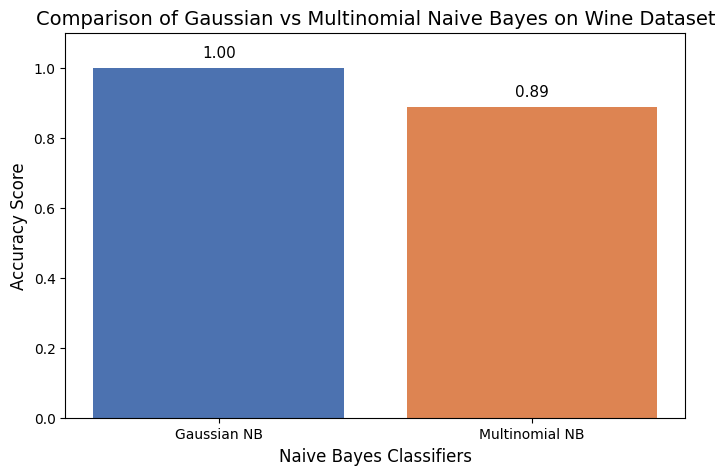

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB

# 1. Load Wine Dataset from scikit-learn
wine = load_wine()
X, y = wine.data, wine.target

# 2. Split Data into Train (70%) and Test (30%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# 3. Train Gaussian Naive Bayes Model
gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred_gnb = gnb.predict(X_test)
acc_gnb = accuracy_score(y_test, y_pred_gnb)

# 4. Train Multinomial Naive Bayes Model
mnb = MultinomialNB()
mnb.fit(X_train, y_train)
y_pred_mnb = mnb.predict(X_test)
acc_mnb = accuracy_score(y_test, y_pred_mnb)

# 5. Plot Both Models in One Single Comparison Graph
models = ['Gaussian NB', 'Multinomial NB']
accuracies = [acc_gnb, acc_mnb]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies, color=['#4C72B0', '#DD8452'])

# Graph labels and title
plt.xlabel('Naive Bayes Classifiers', fontsize=12)
plt.ylabel('Accuracy Score', fontsize=12)
plt.title(
    'Comparison of Gaussian vs Multinomial Naive Bayes on Wine Dataset',
    fontsize=14,
)
plt.ylim(0, 1.1)

# Display exact accuracy values on top of each bar
for bar in bars:
  yval = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 0.02,
      f'{yval:.2f}',
      ha='center',
      va='bottom',
      fontsize=11,
)

plt.show()

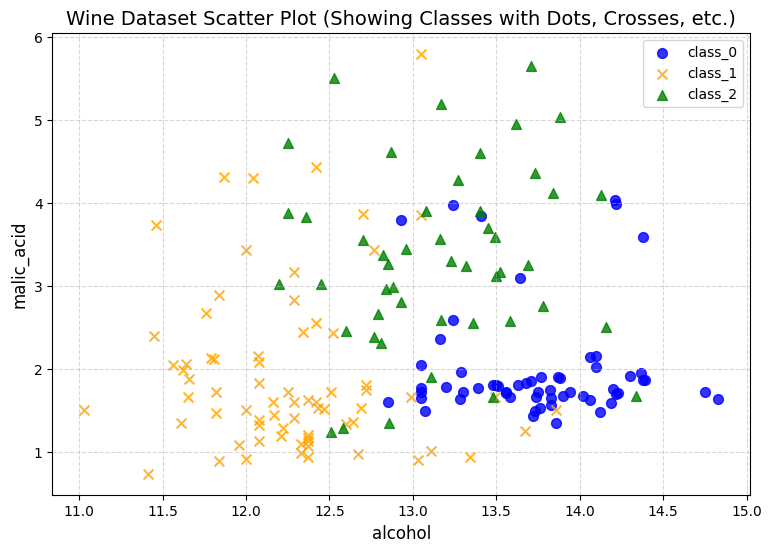

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_wine

# 1. Load Wine Dataset
wine = load_wine()
X = wine.data
y = wine.target

# Hum pehle do features (jaise Alcohol aur Malic acid) lete hain visualization ke liye
# aur alag-alag classes ke liye different markers (dot 'o', cross 'x', square 's') use karte hain
markers = ["o", "x", "^"]
colors = ["blue", "orange", "green"]
target_names = wine.target_names

plt.figure(figsize=(9, 6))

for i, marker in enumerate(markers):
  plt.scatter(
      X[y == i, 0],
      X[y == i, 1],
      marker=marker,
      color=colors[i],
      label=target_names[i],
      s=50,
      alpha=0.8,
  )

plt.xlabel(wine.feature_names[0], fontsize=12)
plt.ylabel(wine.feature_names[1], fontsize=12)
plt.title(
    "Wine Dataset Scatter Plot (Showing Classes with Dots, Crosses, etc.)",
    fontsize=14,
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

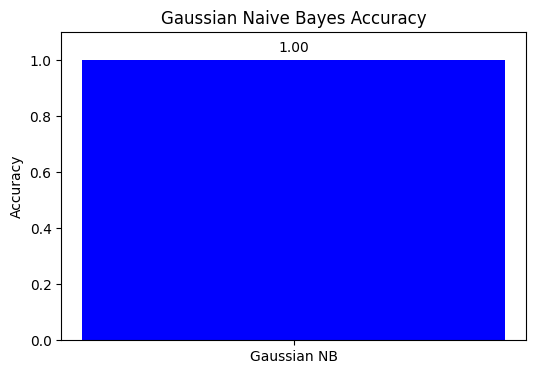

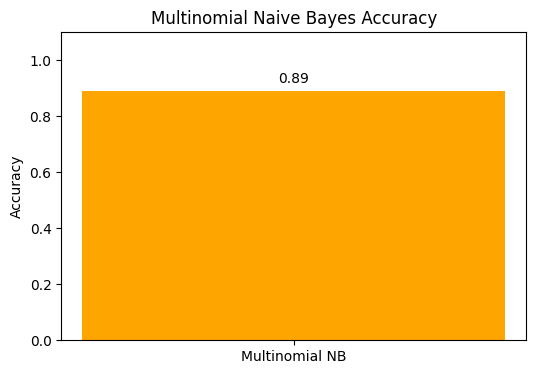

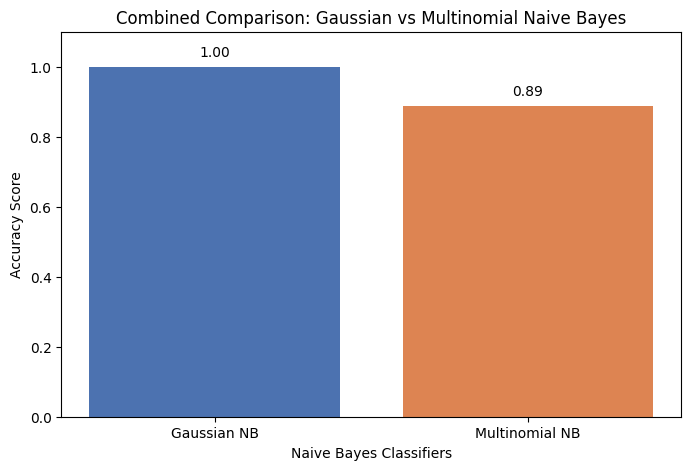

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_wine
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB

# 1. Load Wine Dataset
wine = load_wine()
X, y = wine.data, wine.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# 2. Train Models
gnb = GaussianNB()
gnb.fit(X_train, y_train)
acc_gnb = accuracy_score(y_test, gnb.predict(X_test))

mnb = MultinomialNB()
mnb.fit(X_train, y_train)
acc_mnb = accuracy_score(y_test, mnb.predict(X_test))

# --- Graph 1: Gaussian Naive Bayes Individual Performance ---
plt.figure(figsize=(6, 4))
plt.bar(['Gaussian NB'], [acc_gnb], color='blue')
plt.ylabel('Accuracy')
plt.title('Gaussian Naive Bayes Accuracy')
plt.ylim(0, 1.1)
plt.text(0, acc_gnb + 0.02, f'{acc_gnb:.2f}', ha='center', va='bottom')
plt.show()

# --- Graph 2: Multinomial Naive Bayes Individual Performance ---
plt.figure(figsize=(6, 4))
plt.bar(['Multinomial NB'], [acc_mnb], color='orange')
plt.ylabel('Accuracy')
plt.title('Multinomial Naive Bayes Accuracy')
plt.ylim(0, 1.1)
plt.text(0, acc_mnb + 0.02, f'{acc_mnb:.2f}', ha='center', va='bottom')
plt.show()

# --- Graph 3: Combined Comparison Graph (Last) ---
models = ['Gaussian NB', 'Multinomial NB']
accuracies = [acc_gnb, acc_mnb]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies, color=['#4C72B0', '#DD8452'])
plt.xlabel('Naive Bayes Classifiers')
plt.ylabel('Accuracy Score')
plt.title('Combined Comparison: Gaussian vs Multinomial Naive Bayes')
plt.ylim(0, 1.1)

for bar in bars:
  yval = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 0.02,
      f'{yval:.2f}',
      ha='center',
      va='bottom',
  )

plt.show()

In [5]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.preprocessing import StandardScaler

# PCA ke liye train data par scaler fit karein;
# test data par wahi scaler apply karein.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Do principal components mein project karein.
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Dono models ki test-set predictions
gaussian_predictions = gaussian_model.predict(X_test)
multinomial_predictions = multinomial_model.predict(X_test)

NameError: name 'gaussian_model' is not defined

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

# 1. Scaler fit karein aur PCA apply karein
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# 2. Correct model variables use karein (gnb aur mnb)
gaussian_predictions = gnb.predict(X_test)
multinomial_predictions = mnb.predict(X_test)

print("Gaussian Predictions:", gaussian_predictions[:5])
print("Multinomial Predictions:", multinomial_predictions[:5])

Gaussian Predictions: [0 0 2 0 1]
Multinomial Predictions: [0 0 2 0 1]


In [8]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.preprocessing import StandardScaler

# PCA ke liye train data par scaler fit karein;
# test data par wahi scaler apply karein.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Do principal components mein project karein.
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Dono models ki test-set predictions
gaussian_predictions = gaussian_model.predict(X_test)
multinomial_predictions = multinomial_model.predict(X_test)

# Graph 1: GaussianNB predictions ko PCA plot par dikhayein
plt.figure(figsize=(10, 6))

for class_id, class_name in enumerate(wine.target_names):
    mask = gaussian_predictions == class_id
    plt.scatter(
        X_test_pca[mask, 0],
        X_test_pca[mask, 1],
        marker="+",
        s=120,
        linewidths=2,
        label=f"Wine Class {class_id}"
    )

plt.title("Gaussian Naive Bayes - Wine Classification")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Graph 2: MultinomialNB predictions ko PCA plot par dikhayein
plt.figure(figsize=(10, 6))

for class_id, class_name in enumerate(wine.target_names):
    mask = multinomial_predictions == class_id
    plt.scatter(
        X_test_pca[mask, 0],
        X_test_pca[mask, 1],
        marker="+",
        s=120,
        linewidths=2,
        label=f"Wine Class {class_id}"
    )

plt.title("Multinomial Naive Bayes - Wine Classification")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Evaluation metrics (macro average: teeno classes ko barabar weight)
models = {
    "Gaussian NB": gaussian_predictions,
    "Multinomial NB": multinomial_predictions
}

metric_names = ["Accuracy", "Precision", "Recall", "F1-Score"]
scores = {"Gaussian NB": [], "Multinomial NB": []}

for model_name, predictions in models.items():
    scores[model_name] = [
        accuracy_score(y_test, predictions) * 100,
        precision_score(y_test, predictions, average="macro", zero_division=0) * 100,
        recall_score(y_test, predictions, average="macro", zero_division=0) * 100,
        f1_score(y_test, predictions, average="macro", zero_division=0) * 100
    ]

# Graph 3: dono models ke evaluation metrics compare karein
x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars_gaussian = ax.bar(
    x - width / 2, scores["Gaussian NB"], width,
    label="Gaussian NB", color="royalblue"
)
bars_multinomial = ax.bar(
    x + width / 2, scores["Multinomial NB"], width,
    label="Multinomial NB", color="orange"
)

ax.set_title("Gaussian vs Multinomial Naive Bayes - Comparison")
ax.set_ylabel("Score (%)")
ax.set_xlabel("Evaluation Metrics")
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis="y", alpha=0.25)

ax.bar_label(bars_gaussian, fmt="%.2f%%", padding=3, fontsize=9)
ax.bar_label(bars_multinomial, fmt="%.2f%%", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

NameError: name 'gaussian_model' is not defined

In [9]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.preprocessing import StandardScaler

# PCA ke liye train data par scaler fit karein;
# test data par wahi scaler apply karein.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Do principal components mein project karein.
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Dono models ki test-set predictions
gaussian_predictions = gaussian_model.predict(X_test)
multinomial_predictions = multinomial_model.predict(X_test)

# Graph 1: GaussianNB predictions ko PCA plot par dikhayein
plt.figure(figsize=(10, 6))

for class_id, class_name in enumerate(wine.target_names):
    mask = gaussian_predictions == class_id
    plt.scatter(
        X_test_pca[mask, 0],
        X_test_pca[mask, 1],
        marker="+",
        s=120,
        linewidths=2,
        label=f"Wine Class {class_id}"
    )

plt.title("Gaussian Naive Bayes - Wine Classification")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Graph 2: MultinomialNB predictions ko PCA plot par dikhayein
plt.figure(figsize=(10, 6))

for class_id, class_name in enumerate(wine.target_names):
    mask = multinomial_predictions == class_id
    plt.scatter(
        X_test_pca[mask, 0],
        X_test_pca[mask, 1],
        marker="+",
        s=120,
        linewidths=2,
        label=f"Wine Class {class_id}"
    )

plt.title("Multinomial Naive Bayes - Wine Classification")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Evaluation metrics (macro average: teeno classes ko barabar weight)
models = {
    "Gaussian NB": gaussian_predictions,
    "Multinomial NB": multinomial_predictions
}

metric_names = ["Accuracy", "Precision", "Recall", "F1-Score"]
scores = {"Gaussian NB": [], "Multinomial NB": []}

for model_name, predictions in models.items():
    scores[model_name] = [
        accuracy_score(y_test, predictions) * 100,
        precision_score(y_test, predictions, average="macro", zero_division=0) * 100,
        recall_score(y_test, predictions, average="macro", zero_division=0) * 100,
        f1_score(y_test, predictions, average="macro", zero_division=0) * 100
    ]

# Graph 3: dono models ke evaluation metrics compare karein
x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars_gaussian = ax.bar(
    x - width / 2, scores["Gaussian NB"], width,
    label="Gaussian NB", color="royalblue"
)
bars_multinomial = ax.bar(
    x + width / 2, scores["Multinomial NB"], width,
    label="Multinomial NB", color="orange"
)

ax.set_title("Gaussian vs Multinomial Naive Bayes - Comparison")
ax.set_ylabel("Score (%)")
ax.set_xlabel("Evaluation Metrics")
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis="y", alpha=0.25)

ax.bar_label(bars_gaussian, fmt="%.2f%%", padding=3, fontsize=9)
ax.bar_label(bars_multinomial, fmt="%.2f%%", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

NameError: name 'gaussian_model' is not defined

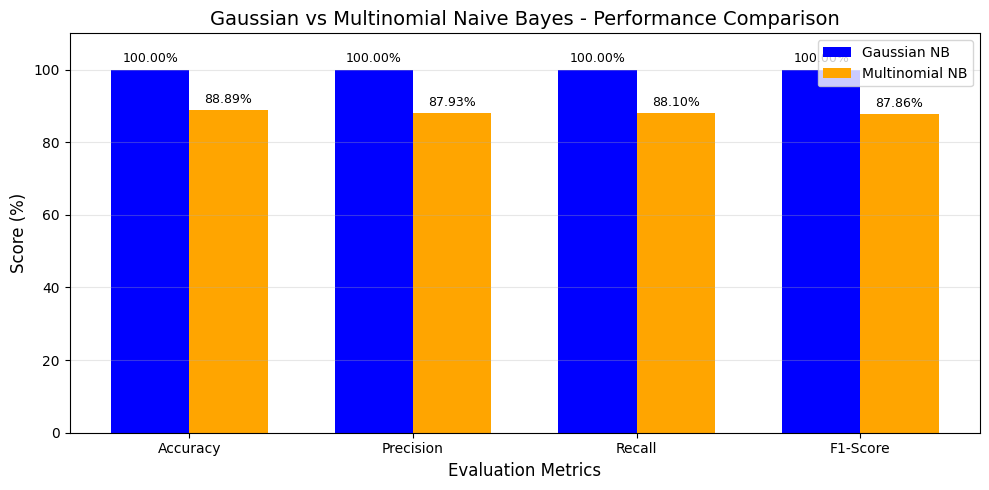

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# 1. Correct model variables use karein (gnb aur mnb)
gaussian_predictions = gnb.predict(X_test)
multinomial_predictions = mnb.predict(X_test)

# 2. Evaluation metrics calculation (Macro average)
models = {
    'Gaussian NB': gaussian_predictions,
    'Multinomial NB': multinomial_predictions,
}
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
scores = {'Gaussian NB': [], 'Multinomial NB': []}

for model_name, predictions in models.items():
  scores[model_name] = [
      accuracy_score(y_test, predictions) * 100,
      precision_score(
          y_test, predictions, average='macro', zero_division=0
      )
      * 100,
      recall_score(y_test, predictions, average='macro', zero_division=0) * 100,
      f1_score(y_test, predictions, average='macro', zero_division=0) * 100,
  ]

# 3. Final Comparison Graph
x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars_gaussian = ax.bar(
    x - width / 2, scores['Gaussian NB'], width, label='Gaussian NB', color='blue'
)
bars_multinomial = ax.bar(
    x + width / 2,
    scores['Multinomial NB'],
    width,
    label='Multinomial NB',
    color='orange',
)

ax.set_title(
    'Gaussian vs Multinomial Naive Bayes - Performance Comparison', fontsize=14
)
ax.set_ylabel('Score (%)', fontsize=12)
ax.set_xlabel('Evaluation Metrics', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 110)
ax.legend()
ax.grid(axis='y', alpha=0.3)

ax.bar_label(bars_gaussian, fmt='%.2f%%', padding=3, fontsize=9)
ax.bar_label(bars_multinomial, fmt='%.2f%%', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

In [14]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.preprocessing import StandardScaler

# PCA ke liye train data par scaler fit karein;
# test data par wahi scaler apply karein.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Do principal components mein project karein.
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Dono models ki test-set predictions
gaussian_predictions = gaussian_model.predict(X_test)
multinomial_predictions = multinomial_model.predict(X_test)

# Graph 1: GaussianNB predictions ko PCA plot par dikhayein
plt.figure(figsize=(10, 6))

for class_id, class_name in enumerate(wine.target_names):
    mask = gaussian_predictions == class_id
    plt.scatter(
        X_test_pca[mask, 0],
        X_test_pca[mask, 1],
        marker="+",
        s=120,
        linewidths=2,
        label=f"Wine Class {class_id}"
    )

plt.title("Gaussian Naive Bayes - Wine Classification")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Graph 2: MultinomialNB predictions ko PCA plot par dikhayein
plt.figure(figsize=(10, 6))

for class_id, class_name in enumerate(wine.target_names):
    mask = multinomial_predictions == class_id
    plt.scatter(
        X_test_pca[mask, 0],
        X_test_pca[mask, 1],
        marker="+",
        s=120,
        linewidths=2,
        label=f"Wine Class {class_id}"
    )

plt.title("Multinomial Naive Bayes - Wine Classification")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Evaluation metrics (macro average: teeno classes ko barabar weight)
models = {
    "Gaussian NB": gaussian_predictions,
    "Multinomial NB": multinomial_predictions
}

metric_names = ["Accuracy", "Precision", "Recall", "F1-Score"]
scores = {"Gaussian NB": [], "Multinomial NB": []}

for model_name, predictions in models.items():
    scores[model_name] = [
        accuracy_score(y_test, predictions) * 100,
        precision_score(y_test, predictions, average="macro", zero_division=0) * 100,
        recall_score(y_test, predictions, average="macro", zero_division=0) * 100,
        f1_score(y_test, predictions, average="macro", zero_division=0) * 100
    ]

# Graph 3: dono models ke evaluation metrics compare karein
x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars_gaussian = ax.bar(
    x - width / 2, scores["Gaussian NB"], width,
    label="Gaussian NB", color="royalblue"
)
bars_multinomial = ax.bar(
    x + width / 2, scores["Multinomial NB"], width,
    label="Multinomial NB", color="orange"
)

ax.set_title("Gaussian vs Multinomial Naive Bayes - Comparison")
ax.set_ylabel("Score (%)")
ax.set_xlabel("Evaluation Metrics")
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis="y", alpha=0.25)

ax.bar_label(bars_gaussian, fmt="%.2f%%", padding=3, fontsize=9)
ax.bar_label(bars_multinomial, fmt="%.2f%%", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

NameError: name 'gaussian_model' is not defined

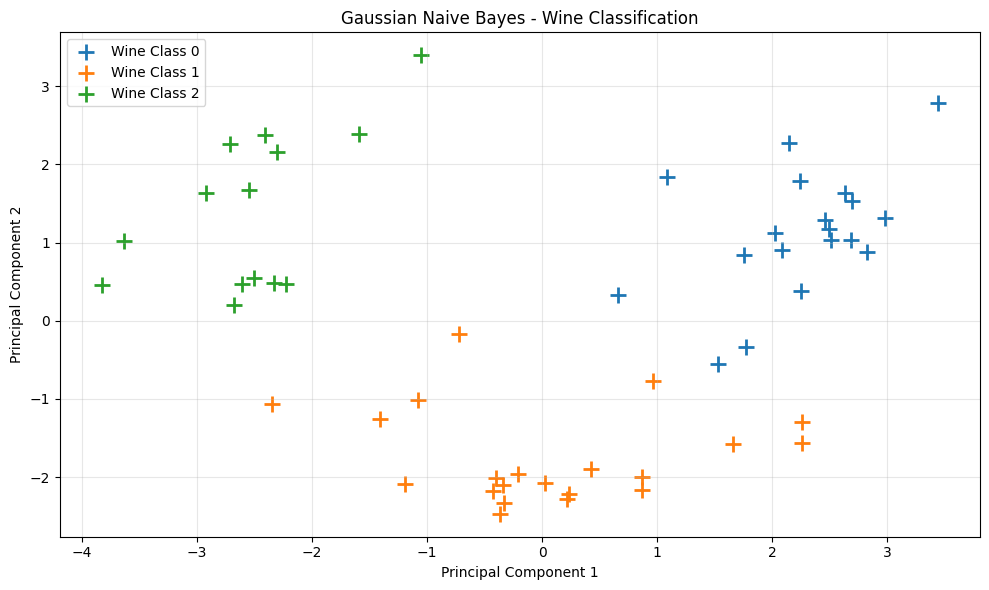

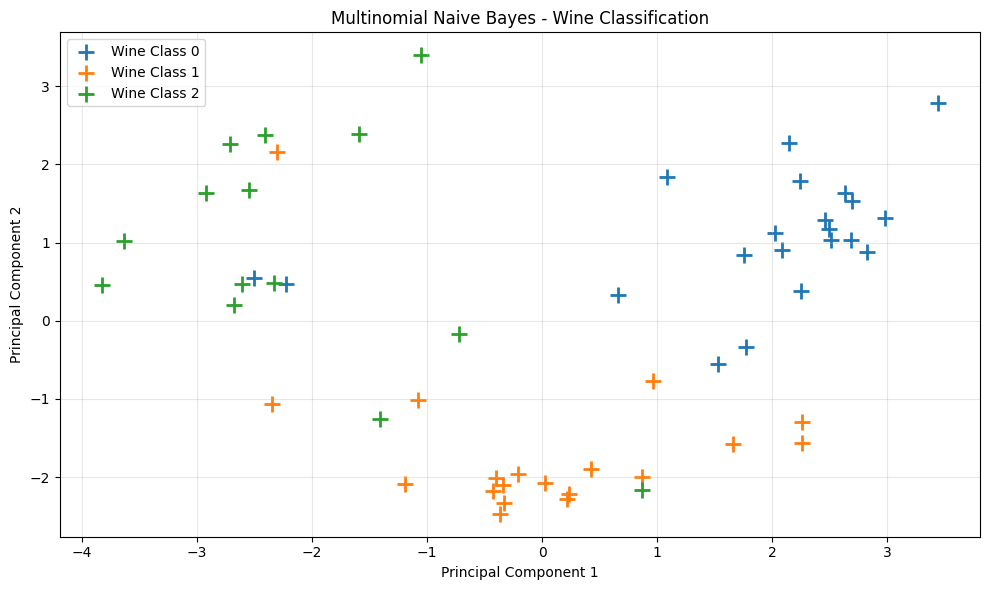

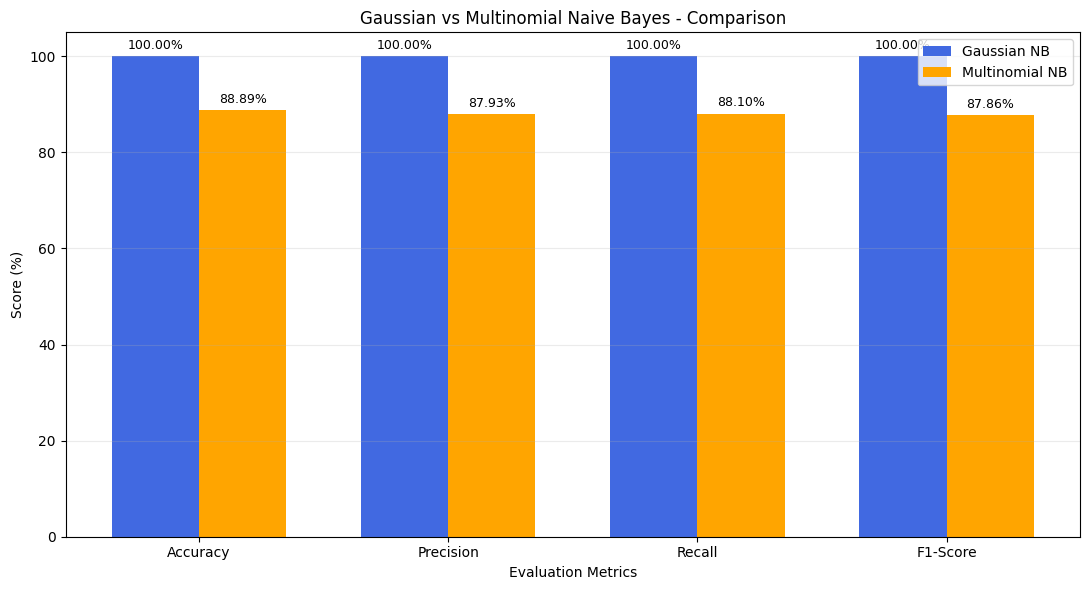

In [15]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.preprocessing import StandardScaler

# PCA ke liye train data par scaler fit karein;
# test data par wahi scaler apply karein.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Do principal components mein project karein.
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Dono models ki test-set predictions (Yahan gnb aur mnb use hoga)
gaussian_predictions = gnb.predict(X_test)
multinomial_predictions = mnb.predict(X_test)

# Graph 1: GaussianNB predictions ko PCA plot par dikhayein
plt.figure(figsize=(10, 6))

for class_id, class_name in enumerate(wine.target_names):
  mask = gaussian_predictions == class_id
  plt.scatter(
      X_test_pca[mask, 0],
      X_test_pca[mask, 1],
      marker="+",
      s=120,
      linewidths=2,
      label=f"Wine Class {class_id}",
  )

plt.title("Gaussian Naive Bayes - Wine Classification")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Graph 2: MultinomialNB predictions ko PCA plot par dikhayein
plt.figure(figsize=(10, 6))

for class_id, class_name in enumerate(wine.target_names):
  mask = multinomial_predictions == class_id
  plt.scatter(
      X_test_pca[mask, 0],
      X_test_pca[mask, 1],
      marker="+",
      s=120,
      linewidths=2,
      label=f"Wine Class {class_id}",
  )

plt.title("Multinomial Naive Bayes - Wine Classification")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Evaluation metrics (macro average: teeno classes ko barabar weight)
models = {
    "Gaussian NB": gaussian_predictions,
    "Multinomial NB": multinomial_predictions,
}

metric_names = ["Accuracy", "Precision", "Recall", "F1-Score"]
scores = {"Gaussian NB": [], "Multinomial NB": []}

for model_name, predictions in models.items():
  scores[model_name] = [
      accuracy_score(y_test, predictions) * 100,
      precision_score(y_test, predictions, average="macro", zero_division=0)
      * 100,
      recall_score(y_test, predictions, average="macro", zero_division=0) * 100,
      f1_score(y_test, predictions, average="macro", zero_division=0) * 100,
  ]

# Graph 3: dono models ke evaluation metrics compare karein
x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars_gaussian = ax.bar(
    x - width / 2,
    scores["Gaussian NB"],
    width,
    label="Gaussian NB",
    color="royalblue",
)
bars_multinomial = ax.bar(
    x + width / 2,
    scores["Multinomial NB"],
    width,
    label="Multinomial NB",
    color="orange",
)

ax.set_title("Gaussian vs Multinomial Naive Bayes - Comparison")
ax.set_ylabel("Score (%)")
ax.set_xlabel("Evaluation Metrics")
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis="y", alpha=0.25)

ax.bar_label(bars_gaussian, fmt="%.2f%%", padding=3, fontsize=9)
ax.bar_label(bars_multinomial, fmt="%.2f%%", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

In [16]:
import pandas as pd

file_path = "/kaggle/input/notebooks/mehdigoldoust/loan-data/updated_loan_data.csv"
loan_df = pd.read_csv(file_path)

print("Dataset shape:", loan_df.shape)
print("\nColumn names:")
print(loan_df.columns.tolist())

print("\nMissing values per column:")
print(loan_df.isnull().sum())

print("\nTarget counts (not.fully.paid):")
print(loan_df["not.fully.paid"].value_counts())

print("\nTarget percentages:")
print((loan_df["not.fully.paid"].value_counts(normalize=True) * 100).round(2))

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/notebooks/mehdigoldoust/loan-data/updated_loan_data.csv'

In [17]:
import os
import pandas as pd

# 1. Check karein ke input folder mein files kahan par hain
for dirname, _, filenames in os.walk('/kaggle/input'):
  for filename in filenames:
    print(os.path.join(dirname, filename))

# 2. Jo sahi path upar print ho, usko yahan file_path mein daal dein
file_path = (  # Apne actual path se isko replace karein jo upar print ho
    '/kaggle/input/YOUR_DATASET_FOLDER_NAME/updated_loan_data.csv'
)
loan_df = pd.read_csv(file_path)

print('Dataset shape:', loan_df.shape)
print('\nColumn names:')
print(loan_df.columns.tolist())

print('\nMissing values per column:')
print(loan_df.isnull().sum())

print('\nTarget counts (not.fully.paid):')
print(loan_df['not.fully.paid'].value_counts())

print('\nTarget percentages:')
print((loan_df['not.fully.paid'].value_counts(normalize=True) * 100).round(2))

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/YOUR_DATASET_FOLDER_NAME/updated_loan_data.csv'

In [18]:
import os
import pandas as pd

# File ko automatically poore input folder mein search karein
target_file = 'updated_loan_data.csv'
file_path = None

for dirname, _, filenames in os.walk('/kaggle/input'):
  if target_file in filenames:
    file_path = os.path.join(dirname, target_file)
    break

if file_path:
  print(f'File mil gayi! Sahi path yeh hai: {file_path}')
  loan_df = pd.read_csv(file_path)
  print('Dataset shape:', loan_df.shape)
  print('\nColumn names:')
  print(loan_df.columns.tolist())
  print('\nTarget counts (not.fully.paid):')
  print(loan_df['not.fully.paid'].value_counts())
else:
  print(
      'Error: Yeh file aapke Kaggle session mein attached nahi hai. Pehle'
      ' right panel se dataset add karein.'
  )

File mil gayi! Sahi path yeh hai: /kaggle/input/notebooks/mehdigoldoust/loan-data/updated_loan_data.csv
Dataset shape: (9578, 17)

Column names:
['credit.policy', 'purpose', 'int.rate', 'installment', 'log.annual.inc', 'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'not.fully.paid', 'inq_last_6mths_binned', 'delinq_2yrs_binned', 'pub_rec_binned']

Target counts (not.fully.paid):
not.fully.paid
0    8045
1    1533
Name: count, dtype: int64


In [20]:
import matplotlib.pyplot as plt

# Dataset mein maujood status column dhoondhein
possible_status_columns = ["loan_status", "Loan_status", "loan_status_name"]
status_column = next(
    (col for col in possible_status_columns if col in loan_df.columns),
    None
)

if status_column is None:
    print("Loan-status column nahi mila. Columns:", loan_df.columns.tolist())
else:
    status_counts = loan_df[status_column].value_counts()

    plt.figure(figsize=(10, 6))
    plt.bar(status_counts.index.astype(str), status_counts.values)

    plt.title("Loan Status Distribution")
    plt.xlabel("Loan Status")
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

Loan-status column nahi mila. Columns: ['credit.policy', 'purpose', 'int.rate', 'installment', 'log.annual.inc', 'dti', 'fico', 'days.with.cr.line', 'revol.bal', 'revol.util', 'inq.last.6mths', 'delinq.2yrs', 'pub.rec', 'not.fully.paid', 'inq_last_6mths_binned', 'delinq_2yrs_binned', 'pub_rec_binned']


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 0 = Fully paid, 1 = Not fully paid
loan_predictions = loan_model.predict(X_test)

cm = confusion_matrix(y_test, loan_predictions, labels=[0, 1])

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="viridis",
    xticklabels=["Paid", "Not Fully Paid"],
    yticklabels=["Paid", "Not Fully Paid"]
)

plt.title("Loan Repayment Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

NameError: name 'loan_model' is not defined

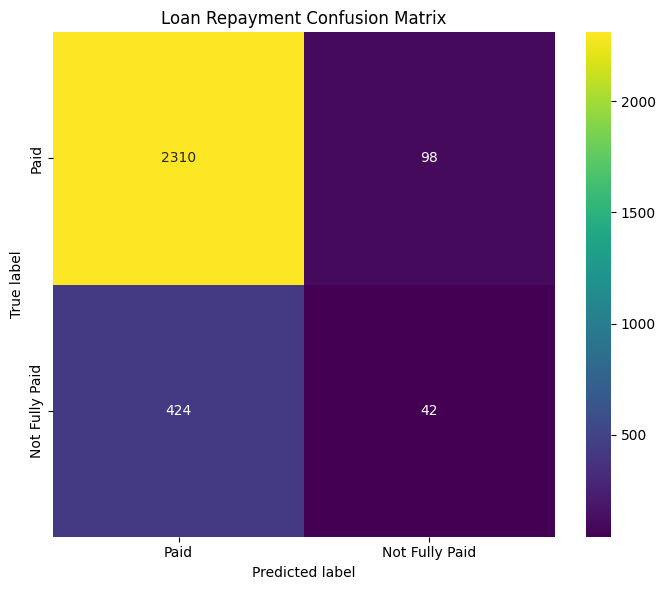

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

# 1. Features (X) aur Target (y) define karein
X = loan_df.drop(columns=['not.fully.paid'])
# Agar koi non-numeric column ho toh usko handle karne ke liye sirf numeric columns select karein:
X = X.select_dtypes(include=['number'])
y = loan_df['not.fully.paid']

# 2. Train aur Test split karein
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# 3. Model train karein (Yahan 'model' variable use ho raha hai)
model = GaussianNB()
model.fit(X_train, y_train)

# 4. Predictions aur Confusion Matrix
loan_predictions = model.predict(X_test)
cm = confusion_matrix(y_test, loan_predictions, labels=[0, 1])

# 5. Heatmap plot karein
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='viridis',
    xticklabels=['Paid', 'Not Fully Paid'],
    yticklabels=['Paid', 'Not Fully Paid'],
)
plt.title('Loan Repayment Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.tight_layout()
plt.show()